# Calidad de datos

## Import y rutas

In [383]:
from pathlib import Path
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [384]:
ROOT_DIR = Path.cwd().parent
RAW_DATA_DIR = ROOT_DIR / "data" / "raw"
PROCESSED_DATA_DIR = ROOT_DIR / "data" / "processed"

RAW_KUEPA_FILE = RAW_DATA_DIR / "Prueba_Tecnica_Analista_Datos_EFE.xlsx" 
PROCESSED_DATA_INCRIPCION = PROCESSED_DATA_DIR / "Inscritos.csv"
PROCESSED_DATA_ACTIVIDAD = PROCESSED_DATA_DIR / "Actividad.csv"
PROCESSED_DATA_EMPLEABILIDAD = PROCESSED_DATA_DIR / "Empleabilidad.csv"


## Carga

In [385]:
# Cargar las hojas específicas del Excel
df_inscritos = pd.read_excel(RAW_KUEPA_FILE, sheet_name='inscritos')
df_actividad = pd.read_excel(RAW_KUEPA_FILE, sheet_name='actividad')
df_empleabilidad = pd.read_excel(RAW_KUEPA_FILE, sheet_name='empleabilidad')

# Verificación rápida
print("Inscritos:", df_inscritos.shape)
print("Actividad:", df_actividad.shape)
print("Empleabilidad:", df_empleabilidad.shape)



Inscritos: (752, 13)
Actividad: (752, 7)
Empleabilidad: (289, 5)


### Validación Incial

In [386]:
#Ver tipos de dato iniciales
df_inscritos.info()
df_actividad.info()
df_empleabilidad.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 752 entries, 0 to 751
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   id_inscrito         752 non-null    object 
 1   documento           752 non-null    object 
 2   nombre              752 non-null    object 
 3   genero              743 non-null    object 
 4   edad                744 non-null    float64
 5   ciudad              752 non-null    object 
 6   proyecto            752 non-null    object 
 7   canal_convocatoria  752 non-null    object 
 8   gestor              752 non-null    object 
 9   estrato             752 non-null    int64  
 10  fecha_inscripcion   752 non-null    object 
 11  correo              749 non-null    object 
 12  celular             748 non-null    object 
dtypes: float64(1), int64(1), object(11)
memory usage: 76.5+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 752 entries, 0 to 751
Data columns (total 7 co

In [387]:
df_inscritos.head(10)

,id_inscrito,documento,nombre,genero,edad,ciudad,proyecto,canal_convocatoria,gestor,estrato,fecha_inscripcion,correo,celular
0,KP-00236,1031017442,Yuli Ramírez Muñoz,F,23.0,Medellín,Ruta Empleo Joven,Redes sociales,G05,3,2026-03-29,yuli6640@hotmail.com,3665190047
1,KP-00054,1072819696,Diego Muñoz Castro,F,18.0,Cali,Ruta Empleo Joven,Redes sociales,G04,1,2026-07-09,diego4938@hotmail.com,3220409766
2,KP-00552,1088197593,Natalia Martínez Vargas,F,18.0,Soacha,Impulsa Mujer,Unidad móvil,G04,1,2026-06-10,natalia4149@hotmail.com,3496891198
3,KP-00223,1024654175,Daniela Vargas Moreno,F,18.0,Bogotá,Ruta Empleo Joven,Aliado,G06,2,2026-06-21,daniela9760@gmail.com,3083154159
4,KP-00620,1033308980,Santiago Suárez Vargas,F,18.0,Bogotá,Impulsa Mujer,Referido,G01,2,2026-02-08,santiago4997@outlook.com,3034353782
5,KP-00729,1.009.141.673,Felipe Gómez Suárez,F,21.0,BOGOTÁ,Impulsa Mujer,Referido,G06,2,2026-06-02,felipe9986@outlook.com,3973606179
6,KP-00404,1019920323,Valentina Rojas Ramírez,F,33.0,Bogotá,Talento Digital,Aliado,G06,3,2026-04-27,valentina8920@outlook.com,3487742099
7,KP-00354,1056590303,Laura Rojas Hernández,F,25.0,Bogotá,Talento Digital,Referido,G04,4,2026-06-10,laura734@hotmail.com,3296084292
8,KP-00347,1041414363,Valentina Cárdenas Pineda,M,25.0,Cali,Talento digital,Redes sociales,G06,2,01/04/2026,valentina5089@gmail.com,3910952037
9,KP-00345,1073872738,Felipe Quintero López,M,16.0,Medellín,Talento Digital,Redes sociales,G05,2,2026-06-02,felipe2847@outlook.com,3530524879


In [388]:
df_actividad.head(10)

,id_inscrito,fecha_primer_ingreso,dias_activos_semana1,modulos_completados,porcentaje_avance,ultima_conexion,estado
0,KP-00224,2026-07-28,4,6,72.1,2026-09-29,Activo
1,KP-00347,2026-04-09,4,8,100.0,2026-06-23,Graduado
2,KP-00410,2026-08-16,1,2,26.4,2026-09-06,Desertor
3,KP-00127,2026-03-11,0,8,100.0,2026-05-29,Graduado
4,KP-00503,NaT,1,0,0.0,NaT,Desertor
5,KP-00465,NaT,0,0,0.0,NaT,Desertor
6,KP-00651,2026-06-27,3,3,33.8,2026-07-28,Desertor
7,KP-00110,2026-08-15,0,4,49.6,2026-09-24,Desertor
8,KP-00539,2026-07-03,0,6,76.4,2026-08-31,Desertor
9,KP-00509,2026-07-17,4,7,86.8,2026-09-28,Activo


In [389]:
df_empleabilidad.head(10)

,id_inscrito,colocado,fecha_colocacion,tipo_contrato,salario
0,KP-00455,No,NaT,NaN,NaN
1,KP-00296,No,NaT,NaN,NaN
2,KP-00488,Sí,2026-09-01,Término fijo,1820000.0
3,KP-00097,No,NaT,NaN,NaN
4,KP-00096,Sí,2026-07-27,Término fijo,2155000.0
5,KP-00223,Sí,2026-09-28,Término fijo,1901000.0
6,KP-00170,No,NaT,NaN,NaN
7,KP-00080,No,NaT,NaN,NaN
8,KP-00709,No,NaT,NaN,NaN
9,KP-00222,Sí,2026-08-05,Término fijo,1697000.0


## Limpieza y Estandarización

### Inscritos

En primer lugar, se realizó la limpieza y estandarización de la tabla inscritos, ya que esta se utilizará como tabla base para validar y relacionar la información de los demás conjuntos de datos.

Para las variables género, ciudad, proyecto y canal de convocatoria, se revisaron inicialmente los valores únicos con el fin de identificar diferencias de escritura, uso de mayúsculas, tildes y otras variaciones. Posteriormente, se unificaron los valores que representaban la misma categoría mediante una convención común. Asimismo, los registros sin información válida se estandarizaron como valores nulos (NaN).


#### Genero

In [390]:

# Valores Unicos
valores_genero = df_inscritos['genero'].value_counts()
print("Valores únicos en 'genero':")
display(valores_genero)

print(f"\nTotal de nulos (NaN): {df_inscritos['genero'].isna().sum()}")
print(f"Total de vacíos (''): {(df_inscritos['genero'].fillna('').astype(str).str.strip() == '').sum()}")

Valores únicos en 'genero':


genero
F            455
M            247
NB            16
Mujer          7
Femenino       5
f              5
Masculino      4
m              3
Hombre         1
Name: count, dtype: int64


Total de nulos (NaN): 9
Total de vacíos (''): 9


In [391]:

# Mapeo
df_inscritos['genero_normalizado'] = df_inscritos['genero'].str.lower().str.strip()
mapeo_genero = {'masculino': 'M', 'm': 'M', 'hombre' : 'M', 
              'femenino': 'F', 'f': 'F' , 'mujer' : 'F',
              'nb' :'NB'}
df_inscritos['genero_final'] = df_inscritos['genero_normalizado'].map(mapeo_genero).fillna(df_inscritos['genero'])
df_inscritos.loc[df_inscritos['genero_final'].isin(['', 'nan', 'NaN']), 'genero_final'] = np.nan

# Verificar el resultado
print("Distribución después de la normalización:")
print(df_inscritos['genero_final'].value_counts())
print(f"\nTotal de nulos (NaN): {df_inscritos['genero_final'].isna().sum()}")


Distribución después de la normalización:
genero_final
F     472
M     255
NB     16
Name: count, dtype: int64

Total de nulos (NaN): 9


#### Edad

Para la variable edad, se analizó la distribución de los datos mediante un gráfico con el objetivo de identificar posibles valores fuera de rango. Se observaron registros con edad igual a 0 y otros con edades superiores a 90 años. Estos casos se consideraron atípicos y fueron marcados como valores nulos (NaN) para su tratamiento posterior.

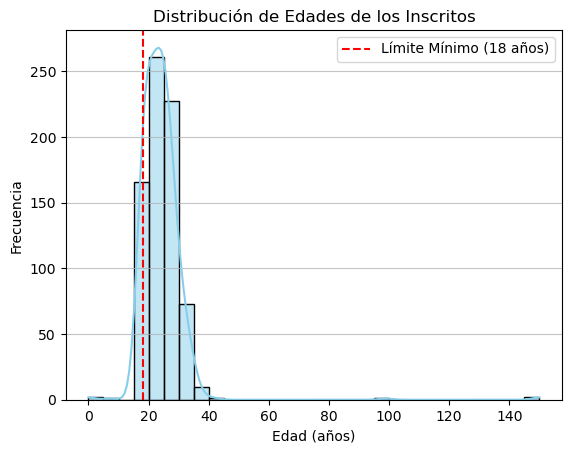

In [392]:
sns.histplot(data=df_inscritos.dropna(subset=['edad']), x='edad', bins=30, kde=True, color='skyblue')

plt.title('Distribución de Edades de los Inscritos')
plt.xlabel('Edad (años)')
plt.ylabel('Frecuencia')
plt.axvline(x=18, color='red', linestyle='--', label='Límite Mínimo (18 años)')
plt.legend()
plt.grid(axis='y', alpha=0.75)

plt.show()

In [393]:
# Identificar menores de edad (< 18)
menores_edad = df_inscritos[(df_inscritos['edad'] < 18) & (df_inscritos['edad']  > 0)]
print(f"\nRegistros con edad menor a 18: {len(menores_edad)}")

# Identificar valores atípicos 
atipicos_altos = df_inscritos[df_inscritos['edad'] > 90]
print(f"Registros con edad mayor a 80: {len(atipicos_altos)}")

# Identificar valores negativos o cero
invalidos_bajos = df_inscritos[df_inscritos['edad'] <= 0]
print(f"Registros con edad <= 0: {len(invalidos_bajos)}")

# Identificar valores nulos
nulos_iniciales = df_inscritos['edad'].isna().sum()
print(f"Registros con nulos {nulos_iniciales}")



Registros con edad menor a 18: 10
Registros con edad mayor a 80: 3
Registros con edad <= 0: 2
Registros con nulos 8


In [394]:
# Definir límites 
edad_min, edad_max = 18, 90
# Aplicar el tratamiento: Marcar como NaN 
df_inscritos.loc[(df_inscritos['edad'] < edad_min) | (df_inscritos['edad'] > edad_max), 'edad'] = np.nan

print(f"Total nulos en edad ahora: {df_inscritos['edad'].isna().sum()}")

Total nulos en edad ahora: 23


#### Ciudad

In [395]:
# Valores Unicos
valores_ciudad = df_inscritos['ciudad'].value_counts()
print("Valores únicos en 'ciudad':")
display(valores_ciudad)

print(f"\nTotal de nulos (NaN): {df_inscritos['ciudad'].isna().sum()}")
print(f"Total de vacíos (''): {(df_inscritos['ciudad'].fillna('').astype(str).str.strip() == '').sum()}")

Valores únicos en 'ciudad':


ciudad
Bogotá          277
Medellín        116
Cali            112
Soacha           98
Barranquilla     79
Bogota           12
bogotá           12
Bta              12
BOGOTÁ D.C.      12
Bogotá D.C       12
BOGOTÁ            6
MEDELLÍN          2
SOACHA            1
BARRANQUILLA      1
Name: count, dtype: int64


Total de nulos (NaN): 0
Total de vacíos (''): 0


In [396]:

#  Mapeo
mapeo_ciudades = {
    'bogotá': 'Bogotá',
    'bogota': 'Bogotá',
    'bogotá d.c.': 'Bogotá',
    'bogotá d.c': 'Bogotá',
    'bta': 'Bogotá',

    'medellín': 'Medellín',
    'medellin': 'Medellín',

    'soacha': 'Soacha',

    'barranquilla': 'Barranquilla',

    'cali': 'Cali'
}

# Aplicar la transformación

df_inscritos['ciudad_normalizada'] = df_inscritos['ciudad'].str.lower().str.strip()
df_inscritos['ciudad_final'] = df_inscritos['ciudad_normalizada'].map(mapeo_ciudades).fillna(df_inscritos['ciudad'])
df_inscritos.loc[df_inscritos['ciudad_final'].isin(['', 'nan', 'NaN']), 'ciudad_final'] = np.nan

#  Verificar el resultado
print("Distribución después de la normalización:")
print(df_inscritos['ciudad_final'].value_counts())

Distribución después de la normalización:
ciudad_final
Bogotá          343
Medellín        118
Cali            112
Soacha           99
Barranquilla     80
Name: count, dtype: int64


#### Proyecto

In [397]:
# Ver valores únicos y su frecuencia
valores_proyecto = df_inscritos['proyecto'].value_counts()
print("Valores únicos en 'proyecto':")
display(valores_proyecto)

# Identificar valores nulos
nulos_proyecto = df_inscritos['proyecto'].isna().sum()
print(f"Registros con nulos {nulos_proyecto}")

Valores únicos en 'proyecto':


proyecto
Ruta Empleo Joven     311
Talento Digital       236
Impulsa Mujer         174
Conecta Territorio     13
Talento digital         6
TALENTO DIGITAL         6
Talento Digital         6
Name: count, dtype: int64

Registros con nulos 0


In [398]:
df_inscritos['proyecto'] = df_inscritos['proyecto'].astype(str).str.strip().str.title()

In [399]:
valores_proyecto = df_inscritos['proyecto'].value_counts()
print("Valores únicos en 'proyecto':")
display(valores_proyecto)

Valores únicos en 'proyecto':


proyecto
Ruta Empleo Joven     311
Talento Digital       254
Impulsa Mujer         174
Conecta Territorio     13
Name: count, dtype: int64

#### Canal Convocatoria

In [400]:
# Ver valores únicos y su frecuencia
valores_canal = df_inscritos['canal_convocatoria'].value_counts()
print("Valores únicos en 'canal_convocatoria':")
display(valores_canal)
# Identificar valores nulos
nulos_proyecto = df_inscritos['proyecto'].isna().sum()
print(f"Registros con nulos {nulos_proyecto}")


Valores únicos en 'canal_convocatoria':


canal_convocatoria
Redes sociales    292
Unidad móvil      195
Aliado            165
Referido          100
Name: count, dtype: int64

Registros con nulos 0


#### Estrato

Para la variable estrato, se validaron tanto los registros nulos como aquellos cuyos valores se encontraban fuera del rango esperado. Dado que esta variable solo puede tomar valores entre 1 y 6, se revisaron los casos que no cumplían con esta condición para identificar posibles errores de captura o inconsistencias en la información.

In [401]:
# Identificar estratos por fuera del rango
estrato_rango = df_inscritos[(df_inscritos['estrato'] < 1) & (df_inscritos['estrato']  > 6)]
print(f"\nRegistros con estrato fuera de rango: {len(estrato_rango)}")
nulos_estrato = df_inscritos['estrato'].isna().sum()
print(f"Registros con nulos {nulos_estrato}")


Registros con estrato fuera de rango: 0
Registros con nulos 0


#### Fecha

Para las variables de fecha, se realizó una validación de los formatos presentes en la información. Se identificaron principalmente dos situaciones: el uso de distintos separadores (- y /) y la coexistencia de los formatos año-mes-día y día-mes-año.

La primera situación fue resuelta de forma automática durante la importación de los datos, ya que la librería utilizada interpretó correctamente ambos separadores. Sin embargo, para el segundo caso fue necesario segmentar los registros en dos grupos según su estructura. Posteriormente, cada grupo se transformó de manera independiente al tipo de dato fecha (datetime) utilizando el formato correspondiente y, una vez completada la conversión, los resultados se reunieron nuevamente en una única columna.

In [402]:

fechas_raw = pd.to_datetime(df_inscritos['fecha_inscripcion'], errors='coerce')
if nulos_iniciales > 0:
    print("\nPrimeras 10 fechas que no se pudieron convertir:")
    
    display(
        df_inscritos.loc[
            fechas_raw.isna(),
            ['fecha_inscripcion']
        ].head(10)
    )
    print(f"No se pudieron convertir: {len(df_inscritos.loc[fechas_raw.isna(), 'fecha_inscripcion'])}")
    
# Identificar valores nulos
nulos_fechas = df_inscritos['fecha_inscripcion'].isna().sum()
print(f"Registros con nulos {nulos_fechas}")


Primeras 10 fechas que no se pudieron convertir:


,fecha_inscripcion
8,01/04/2026
30,06/03/2026
42,24/07/2026
91,20/04/2026
101,09/07/2026
104,21/04/2026
106,29/05/2026
141,12/07/2026
147,25/02/2026
158,19/03/2026


No se pudieron convertir: 40
Registros con nulos 0


In [403]:
fechas = pd.to_datetime(
    df_inscritos['fecha_inscripcion'],
    errors='coerce'
)

faltantes = fechas.isna()

fechas.loc[faltantes] = pd.to_datetime(
    df_inscritos.loc[faltantes, 'fecha_inscripcion'],
    format='%d/%m/%Y',
    errors='coerce'
)

df_inscritos['fecha_inscripcion'] = fechas

In [404]:
print("--- Diagnóstico de Fechas ---")
fechas_raw = pd.to_datetime(df_inscritos['fecha_inscripcion'], errors='coerce')
nulos_iniciales = fechas_raw.isna().sum()
print(f"Fechas inválidas con conversión estándar: {nulos_iniciales}")


--- Diagnóstico de Fechas ---
Fechas inválidas con conversión estándar: 0


#### Celular


En el caso de la columna celular, se identificaron tres situaciones principales: registros sin información, números almacenados con el prefijo internacional +57 o 57, y números con una longitud inferior a la esperada.

Para los casos que incluían prefijos, se realizó primero una normalización de los datos, eliminando espacios, guiones y otros caracteres no numéricos. Posteriormente, se removió el prefijo 57 cuando el número contenía 12 dígitos, ya que correspondía al código de país seguido de un número celular colombiano válido.

Finalmente, se estableció como criterio de calidad que los números con menos de 10 dígitos correspondían probablemente a errores de digitación o registros incompletos. Por esta razón, dichos valores fueron marcados como nulos (NaN), al igual que los registros que inicialmente no contenían información.

In [405]:
# Verificar nulos
nulos_cel = df_inscritos['celular'].isna().sum()
print(f"Registros con celular nulo: {nulos_cel}")
#Verificar longitud actual de los strings
df_inscritos['len_cel'] = df_inscritos['celular'].astype(str).str.len()
print("\nEstadísticas de longitud del string celular:")
print(df_inscritos['len_cel'].describe())


#Identificar registros con prefijo +57 o 57 al inicio
tiene_prefijo = df_inscritos['celular'].astype(str).str.startswith('57') | df_inscritos['celular'].astype(str).str.startswith('+57')
print(f"\nRegistros que inician con 57 o +57: {tiene_prefijo.sum()}")

# Mostrar ejemplos de los que tienen prefijo 
if tiene_prefijo.any():
    print("\nEjemplos de celulares con prefijo:")
    display(df_inscritos[tiene_prefijo][['id_inscrito', 'celular']].head(10))

#Verificar longitudes extremas 
longitudes_raras = df_inscritos[
    (df_inscritos['len_cel'] < 10) | (df_inscritos['len_cel'] > 12)
]
if not longitudes_raras.empty:
    print(f"\nRegistros con longitud de celular sospechosa: {len(longitudes_raras)}")
    display(longitudes_raras[['id_inscrito', 'celular', 'len_cel']].head(100))

Registros con celular nulo: 4

Estadísticas de longitud del string celular:
count    752.000000
mean       9.978723
std        0.635878
min        3.000000
25%       10.000000
50%       10.000000
75%       10.000000
max       13.000000
Name: len_cel, dtype: float64

Registros que inician con 57 o +57: 8

Ejemplos de celulares con prefijo:


,id_inscrito,celular
66,KP-00535,57 3288559902
117,KP-00075,+573209710116
119,KP-00458,+573117080097
336,KP-00400,57 3567506141
395,KP-00042,57 3321458609
450,KP-00574,57 3746152142
678,KP-00632,+573124994829
705,KP-00350,+573735263151



Registros con longitud de celular sospechosa: 16


,id_inscrito,celular,len_cel
66,KP-00535,57 3288559902,13
90,KP-00253,3019108,7
116,KP-00317,NaN,3
117,KP-00075,+573209710116,13
119,KP-00458,+573117080097,13
127,KP-00448,3067081,7
224,KP-00210,3921939,7
336,KP-00400,57 3567506141,13
338,KP-00163,NaN,3
393,KP-00529,NaN,3


In [406]:
# Limpiar caracteres no numéricos (+, espacios, guiones)
df_inscritos['celular_limpio'] = df_inscritos['celular'].astype(str).str.replace(r'\D', '', regex=True)

# Quitar el prefijo 57 solo si tiene 12 dígitos
condicion_prefijo = (df_inscritos['celular_limpio'].str.len() == 12) & (df_inscritos['celular_limpio'].str.startswith('57'))

df_inscritos.loc[condicion_prefijo, 'celular_limpio'] = df_inscritos.loc[condicion_prefijo, 'celular_limpio'].str[2:]


# Dejar únicamente celulares válidos de 10 dígitos
df_inscritos['celular_limpio'] = (df_inscritos['celular_limpio'] .where(df_inscritos['celular_limpio'].str.len() == 10, np.nan)
)
# Verificación rápida
print("Longitudes después de limpieza:")
print(df_inscritos['celular_limpio'].str.len().value_counts())

Longitudes después de limpieza:
celular_limpio
10.0    744
Name: count, dtype: int64


#### Documento

Para la variable documento de identidad, no se encontraron valores nulos. No obstante, se identificaron diferencias en el formato de registro, principalmente por la presencia de caracteres como puntos utilizados como separadores de miles. Estos caracteres fueron removidos para conservar un formato homogéneo basado únicamente en valores numéricos.

In [407]:

# Verificar nulos
nulos_doc = df_inscritos['documento'].isna().sum()
print(f"Registros con documento nulo: {nulos_doc}")

# Verificar longitud de los strings
df_inscritos['len_doc'] = df_inscritos['documento'].astype(str).str.len()
print("\nEstadísticas de longitud del string documento:")
print(df_inscritos['len_doc'].describe())

# Identificar registros con caracteres no numéricos
tiene_no_numericos = df_inscritos['documento'].astype(str).str.contains(r'\D', na=False)
print(f"\nRegistros con caracteres no numéricos (puntos, guiones, etc.): {tiene_no_numericos.sum()}")

# Mostrar ejemplos de los que tienen caracteres especiales
if tiene_no_numericos.any():
    print("\nEjemplos de documentos con formato sucio:")
    display(df_inscritos[tiene_no_numericos][['id_inscrito', 'documento']].head(10))

Registros con documento nulo: 0

Estadísticas de longitud del string documento:
count    752.000000
mean      10.047872
std        0.376183
min       10.000000
25%       10.000000
50%       10.000000
75%       10.000000
max       13.000000
Name: len_doc, dtype: float64

Registros con caracteres no numéricos (puntos, guiones, etc.): 12

Ejemplos de documentos con formato sucio:


,id_inscrito,documento
5,KP-00729,1.009.141.673
67,KP-00728,1.078.676.825
107,KP-00725,1.078.396.523
171,KP-00732,1.009.288.854
178,KP-00734,1.032.133.769
297,KP-00726,1.085.949.938
413,KP-00730,1.054.391.465
434,KP-00724,1.086.701.248
612,KP-00723,1.052.938.372
650,KP-00727,1.033.308.980


In [408]:
df_inscritos['documento_limpio'] = df_inscritos['documento'].astype(str).str.replace(r'\D', '', regex=True)
df_inscritos.loc[df_inscritos['documento_limpio'] == '', 'documento_limpio'] = np.nan


In [409]:
# Verificar longitud de los strings 
df_inscritos['len_doc'] = df_inscritos['documento_limpio'].astype(str).str.len()
print("\nEstadísticas de longitud del string documento:")
print(df_inscritos['len_doc'].describe())

# Identificar registros con caracteres no numéricos
tiene_no_numericos = df_inscritos['documento_limpio'].astype(str).str.contains(r'\D', na=False)
print(f"\nRegistros con caracteres no numéricos (puntos, guiones, etc.): {tiene_no_numericos.sum()}")




Estadísticas de longitud del string documento:
count    752.0
mean      10.0
std        0.0
min       10.0
25%       10.0
50%       10.0
75%       10.0
max       10.0
Name: len_doc, dtype: float64

Registros con caracteres no numéricos (puntos, guiones, etc.): 0


#### Id

In [410]:
duplicados_id = df_inscritos.duplicated(subset=['id_inscrito'], keep=False)
print(f"Registros con id_inscrito duplicado: {duplicados_id.sum()}")
# Identificar valores nulos
nulos_id = df_inscritos['id_inscrito'].isna().sum()
print(f"Registros con nulos {nulos_id}")

Registros con id_inscrito duplicado: 0
Registros con nulos 0


#### Limpieza

In [411]:
# Sobrescribir columnas originales con las versiones limpias
df_inscritos['genero'] = df_inscritos['genero_final']
df_inscritos['ciudad'] = df_inscritos['ciudad_final']
df_inscritos['celular'] = df_inscritos['celular_limpio']
df_inscritos['documento'] = df_inscritos['documento_limpio']

# Eliminar columnas auxiliares
columnas_a_eliminar = [
    'genero_normalizado', 'genero_final', 
    'ciudad_normalizada', 'ciudad_final', 
    'len_cel', 'celular_limpio', 
    'len_doc', 'documento_limpio'
]

df_inscritos.drop(columns=columnas_a_eliminar, inplace=True)

#Verificación final de la estructura limpia
print("Estructura final de df_inscritos:")
df_inscritos.info()

Estructura final de df_inscritos:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 752 entries, 0 to 751
Data columns (total 13 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   id_inscrito         752 non-null    object        
 1   documento           752 non-null    object        
 2   nombre              752 non-null    object        
 3   genero              743 non-null    object        
 4   edad                729 non-null    float64       
 5   ciudad              752 non-null    object        
 6   proyecto            752 non-null    object        
 7   canal_convocatoria  752 non-null    object        
 8   gestor              752 non-null    object        
 9   estrato             752 non-null    int64         
 10  fecha_inscripcion   752 non-null    datetime64[ns]
 11  correo              749 non-null    object        
 12  celular             744 non-null    object        
dtypes: datetime64[ns

#### Inscritos Unicos

Una vez completada la limpieza de la información, se procedió a validar la cantidad de inscritos únicos. Para ello, primero se verificó que no existieran identificadores de inscripción (id_inscrito) duplicados. Posteriormente, se revisó la existencia de documentos de identidad repetidos entre los registros.

En esta segunda validación se identificaron 30 documentos duplicados. Sin embargo, antes de considerarlos como registros erróneos, se realizó una revisión más detallada utilizando la combinación de documento de identidad y proyecto. Esta validación permitió confirmar que 30 personas se encontraban registradas más de una vez en el mismo proyecto

In [412]:
# Verificar duplicados en id_inscrito 
duplicados_id = df_inscritos.duplicated(subset=['id_inscrito'], keep=False)
print(f"Registros con id_inscrito duplicado: {duplicados_id.sum()}")

# Verificar duplicados en documento
duplicados_documento = df_inscritos.duplicated(subset=['documento'], keep=False)
print(f"Registros con duplicado de documento: {duplicados_documento.sum()}")


Registros con id_inscrito duplicado: 0
Registros con duplicado de documento: 60


In [413]:
# Verificar duplicados lógicos: misma persona inscrita al mismo proyecto más de una vez
duplicados_logicos = df_inscritos.duplicated(subset=['documento', 'proyecto'], keep=False)
print(f"Registros con duplicado lógico (misma persona, mismo proyecto): {duplicados_logicos.sum()}")
# Mostrar ejemplos si existen para tomar la decisión
if duplicados_logicos.any():
    print("\nMuestra de duplicados lógicos:")
    display(df_inscritos[duplicados_logicos][['id_inscrito', 'documento', 'nombre', 'proyecto', 'fecha_inscripcion']].head(10))

Registros con duplicado lógico (misma persona, mismo proyecto): 60

Muestra de duplicados lógicos:


,id_inscrito,documento,nombre,proyecto,fecha_inscripcion
4,KP-00620,1033308980,Santiago Suárez Vargas,Impulsa Mujer,2026-02-08
5,KP-00729,1009141673,Felipe Gómez Suárez,Impulsa Mujer,2026-06-02
6,KP-00404,1019920323,Valentina Rojas Ramírez,Talento Digital,2026-04-27
14,KP-00751,1012833107,Santiago López Vargas,Impulsa Mujer,2026-06-27
27,KP-00752,1075601914,Natalia Rodríguez Moreno,Impulsa Mujer,2026-06-04
37,KP-00562,1036647328,Andrés Vargas Ortiz,Impulsa Mujer,2026-04-28
54,KP-00691,1031690095,Steven Díaz Ramírez,Impulsa Mujer,2026-04-07
63,KP-00129,1075952763,Jhon Moreno Rojas,Ruta Empleo Joven,2026-02-14
67,KP-00728,1078676825,Juan Gómez Muñoz,Impulsa Mujer,2026-04-18
72,KP-00742,1037526366,Camila Moreno Quintero,Ruta Empleo Joven,2026-07-28


##### Cruce de información

Con la información de inscritos ya depurada, fue necesario cruzarla con la tabla actividad para identificar a qué inscripción correspondía cada registro de seguimiento.

Este proceso se llevó a cabo en dos etapas. En primer lugar, se verificó que no existieran registros duplicados en la tabla actividad a nivel de id_inscrito. Posteriormente, se realizó el cruce entre la tabla actividad y la tabla inscritos para validar la correspondencia entre ambas fuentes de información.

Como resultado, se identificó que la actividad de un participante siempre se asociaba a la inscripción más antigua cuando existían múltiples registros de inscripción para una misma persona.

In [414]:
duplicados_id_actividad = df_actividad.duplicated(subset=['id_inscrito'], keep=False)
print(f"Registros con id_inscrito duplicado: {duplicados_id_actividad.sum()}")
# Identificar valores nulos
nulos_id_actividad = df_actividad['id_inscrito'].isna().sum()
print(f"Registros con nulos {nulos_id_actividad}")

Registros con id_inscrito duplicado: 0
Registros con nulos 0


In [415]:


# Identificar los documentos+proyecto que están duplicados
duplicados_mask = df_inscritos.duplicated(subset=['documento', 'proyecto'], keep=False)
df_duplicados_raw = df_inscritos[duplicados_mask].copy()

#  Ordenarlos para facilitar lectura
df_duplicados_raw = df_duplicados_raw.sort_values(by=['documento', 'proyecto', 'fecha_inscripcion'])

# Cruzar con la tabla de actividad para ver el desempeño de cada ID
df_validacion = df_duplicados_raw.merge(
    df_actividad[['id_inscrito', 'modulos_completados', 'porcentaje_avance', 'estado', 'ultima_conexion']], 
    on='id_inscrito', 
    how='left'
)

#Seleccionar solo las columnas clave 
columnas_clave = [
    'id_inscrito', 'documento', 'proyecto', 'fecha_inscripcion', 
    'modulos_completados', 'porcentaje_avance', 'estado', 'ultima_conexion'
]

print(f"Total de registros involucrados en duplicados lógicos: {len(df_validacion)}")
display(df_validacion[columnas_clave].head(60)) 

Total de registros involucrados en duplicados lógicos: 60


,id_inscrito,documento,proyecto,fecha_inscripcion,modulos_completados,porcentaje_avance,estado,ultima_conexion
0,KP-00592,1009141673,Impulsa Mujer,2026-05-19,8,100.0,Graduado,2026-08-12
1,KP-00729,1009141673,Impulsa Mujer,2026-06-02,0,0.0,Desertor,NaT
2,KP-00013,1009288854,Ruta Empleo Joven,2026-02-19,8,100.0,Graduado,2026-05-18
3,KP-00732,1009288854,Ruta Empleo Joven,2026-03-05,0,0.0,Desertor,NaT
4,KP-00034,1011963213,Ruta Empleo Joven,2026-03-28,0,0.0,Desertor,NaT
5,KP-00739,1011963213,Ruta Empleo Joven,2026-03-31,0,0.0,Desertor,NaT
6,KP-00651,1012833107,Impulsa Mujer,2026-06-25,3,33.8,Desertor,2026-07-28
7,KP-00751,1012833107,Impulsa Mujer,2026-06-27,0,0.0,Desertor,NaT
8,KP-00283,1013644225,Ruta Empleo Joven,2026-04-08,4,52.2,Desertor,2026-05-15
9,KP-00741,1013644225,Ruta Empleo Joven,2026-04-17,0,0.0,Desertor,NaT


In [416]:
len(df_inscritos)

752

#### Limpieza de id_inscrito 

In [417]:
#  Ordenar por fecha de inscripción 
df_sorted = df_inscritos.sort_values(by='fecha_inscripcion', ascending=True)

# Eliminar duplicados lógicos conservando el primero (el más antiguo)
df_inscritos_unicos = df_sorted.drop_duplicates(subset=['documento', 'proyecto'], keep='first')

print(f"Registros iniciales: {len(df_inscritos)}")
print(f"Registros únicos finales: {len(df_inscritos_unicos)}")
print(f"Duplicados eliminados: {len(df_inscritos) - len(df_inscritos_unicos)}")

Registros iniciales: 752
Registros únicos finales: 722
Duplicados eliminados: 30


In [418]:
df_inscritos_unicos.head()

,id_inscrito,documento,nombre,genero,edad,ciudad,proyecto,canal_convocatoria,gestor,estrato,fecha_inscripcion,correo,celular
187,KP-00670,1081624071,Camila Ortiz Pineda,F,20.0,Bogotá,Impulsa Mujer,Redes sociales,G04,2,2026-02-03,camila7001@outlook.com,3188692956
474,KP-00557,1060304725,Angie Ramírez Gómez,F,25.0,Bogotá,Impulsa Mujer,Redes sociales,G05,1,2026-02-04,angie5826@gmail.com,3055349000
580,KP-00462,1086701248,Cristian Ortiz Torres,F,27.0,Bogotá,Talento Digital,Redes sociales,G05,2,2026-02-04,cristian5126@outlook.com,3678766397
604,KP-00590,1048716090,Steven López Ramírez,F,30.0,Barranquilla,Impulsa Mujer,Aliado,G03,2,2026-02-04,steven3015@hotmail.com,3955668334
391,KP-00165,1099940210,Juan Muñoz Gómez,F,18.0,Cali,Ruta Empleo Joven,Redes sociales,G03,1,2026-02-04,juan9400@gmail.com,3746909335


### Actividad

#### Id

In [419]:
duplicados_id_actividad = df_actividad.duplicated(subset=['id_inscrito'], keep=False)
print(f"Registros con id_inscrito duplicado: {duplicados_id_actividad.sum()}")
# Identificar valores nulos
nulos_id_actividad = df_actividad['id_inscrito'].isna().sum()
print(f"Registros con nulos {nulos_id_actividad}")

Registros con id_inscrito duplicado: 0
Registros con nulos 0


In [420]:
# Lista de IDs válidos
ids_validos = set(df_inscritos_unicos['id_inscrito'])

# Filtrar Actividad
df_actividad_limpia = df_actividad[df_actividad['id_inscrito'].isin(ids_validos)].copy()
print(f"Actividad antes: {len(df_actividad)}, después: {len(df_actividad_limpia)}")


Actividad antes: 752, después: 722


#### fecha primer ingreso

In [421]:

fechas_raw_actividad_ingreso = pd.to_datetime(df_actividad_limpia['fecha_primer_ingreso'], errors='coerce')
nulos_ingreso = fechas_raw_actividad_ingreso.isna().sum()
if nulos_ingreso > 0:
    print("\nPrimeras 10 fechas que no se pudieron convertir:")
    display(df_actividad_limpia[fechas_raw_actividad_ingreso.isna()][['id_inscrito', 'fecha_primer_ingreso']].head(10))

    

print(f"Registros con nulos {nulos_ingreso}")


Primeras 10 fechas que no se pudieron convertir:


,id_inscrito,fecha_primer_ingreso
4,KP-00503,NaT
5,KP-00465,NaT
13,KP-00372,NaT
22,KP-00288,NaT
24,KP-00052,NaT
37,KP-00398,NaT
44,KP-00558,NaT
45,KP-00366,NaT
58,KP-00371,NaT
65,KP-00112,NaT


Registros con nulos 110


#### Dias Activos

In [422]:
df_actividad_limpia['dias_activos_semana1'].info()

<class 'pandas.core.series.Series'>
Index: 722 entries, 0 to 751
Series name: dias_activos_semana1
Non-Null Count  Dtype
--------------  -----
722 non-null    int64
dtypes: int64(1)
memory usage: 11.3 KB


In [423]:
# Identificar valores nulos
nulos_dias_actividad = df_actividad_limpia['dias_activos_semana1'].isna().sum()
print(f"Registros con nulos {nulos_dias_actividad}")

Registros con nulos 0


#### Modulos Completados

In [424]:
df_actividad_limpia['modulos_completados'].info()

<class 'pandas.core.series.Series'>
Index: 722 entries, 0 to 751
Series name: modulos_completados
Non-Null Count  Dtype
--------------  -----
722 non-null    int64
dtypes: int64(1)
memory usage: 11.3 KB


In [425]:
# Identificar valores fuera de rango
invalidos_dias_modulos = df_actividad_limpia[(df_actividad_limpia['modulos_completados'] < 0) | (df_actividad_limpia['modulos_completados'] > 8)]
print(f"Registros con valores inválidos: {len(invalidos_dias_modulos)}")


Registros con valores inválidos: 0


#### Porcentaje de avance

In [426]:
df_actividad_limpia['porcentaje_avance'].info()

<class 'pandas.core.series.Series'>
Index: 722 entries, 0 to 751
Series name: porcentaje_avance
Non-Null Count  Dtype  
--------------  -----  
722 non-null    float64
dtypes: float64(1)
memory usage: 11.3 KB


In [427]:
# Identificar valores fuera de rango
invalidos_porcentaje = df_actividad_limpia[(df_actividad_limpia['porcentaje_avance'] < 0 ) | (df_actividad_limpia['porcentaje_avance'] > 100 )  ]
print(f"Registros con valores inválidos: {len(invalidos_porcentaje)}")
display(invalidos_porcentaje)
 

Registros con valores inválidos: 4


,id_inscrito,fecha_primer_ingreso,dias_activos_semana1,modulos_completados,porcentaje_avance,ultima_conexion,estado
72,KP-00036,2026-07-31,2,6,112.5,2026-09-26,Activo
345,KP-00507,2026-05-02,1,5,150.0,2026-06-21,Desertor
388,KP-00053,2026-08-01,0,5,125.0,2026-09-14,Activo
662,KP-00221,2026-04-26,2,5,150.0,2026-06-12,Desertor


In [428]:
df_actividad_limpia.loc[df_actividad_limpia['porcentaje_avance'] > 100, 'porcentaje_avance'] = df_actividad_limpia['modulos_completados']*100/8


#### fecha ultima conexión

In [429]:

fechas_raw_ultima_conexion = pd.to_datetime(df_actividad_limpia['fecha_primer_ingreso'], errors='coerce')
nulos_conexion = fechas_raw_ultima_conexion.isna().sum()

if nulos_conexion > 0:
    print("\nPrimeras 10 fechas que no se pudieron convertir:")
    
    display(df_actividad_limpia[fechas_raw_ultima_conexion.isna()][['id_inscrito', 'fecha_primer_ingreso']].head(10))
    
    
print(f"Registros con nulos {nulos_conexion}")






Primeras 10 fechas que no se pudieron convertir:


,id_inscrito,fecha_primer_ingreso
4,KP-00503,NaT
5,KP-00465,NaT
13,KP-00372,NaT
22,KP-00288,NaT
24,KP-00052,NaT
37,KP-00398,NaT
44,KP-00558,NaT
45,KP-00366,NaT
58,KP-00371,NaT
65,KP-00112,NaT


Registros con nulos 110


In [430]:
inconsistentes = df_actividad_limpia[
    df_actividad_limpia['fecha_primer_ingreso'].isna() !=
    df_actividad_limpia['ultima_conexion'].isna()
]

print(f"Registros inconsistentes: {len(inconsistentes)}")

Registros inconsistentes: 0


#### Estado

In [431]:
df_actividad_limpia['estado'].info()


<class 'pandas.core.series.Series'>
Index: 722 entries, 0 to 751
Series name: estado
Non-Null Count  Dtype 
--------------  ----- 
722 non-null    object
dtypes: object(1)
memory usage: 27.4+ KB


In [432]:
# Identificar valores nulos
nulos_dias_actividad = df_actividad_limpia['dias_activos_semana1'].isna().sum()
print(f"Registros con nulos {nulos_dias_actividad}")

Registros con nulos 0


In [433]:
# Valores Unicos
valores_estado = df_actividad_limpia['estado'].value_counts()
print("Valores únicos en 'estado':")
display(valores_estado)

Valores únicos en 'estado':


estado
Desertor    339
Graduado    284
Activo       99
Name: count, dtype: int64

In [434]:
# Calcular días desde la primera conexión hasta la ultima
df_actividad_limpia['dias_sin_conexion'] = (df_actividad_limpia['fecha_primer_ingreso']- df_actividad_limpia['ultima_conexion']).dt.days

# Identificar "Activos" con más de 12 semanas  sin conexión
inconsistencia_activos = df_actividad_limpia[
    (df_actividad_limpia['estado'] == 'Activo') & 
    (df_actividad_limpia['dias_sin_conexion'] > 84)
]

print(f"Estudiantes 'Activos' con más de 12 semanas sin conexión: {len(inconsistencia_activos)}")

Estudiantes 'Activos' con más de 12 semanas sin conexión: 0


In [435]:
graduados_inconsistentes = df_actividad_limpia[(df_actividad_limpia['estado'] == 'Graduado') &
    (
        (df_actividad_limpia['modulos_completados'] != 8) |
        (df_actividad_limpia['porcentaje_avance'] != 100)
    )
].copy()
fecha_corte = pd.Timestamp('2026-09-30')
graduados_inconsistentes['semanas_inactividad'] = (graduados_inconsistentes['ultima_conexion'] - graduados_inconsistentes['fecha_primer_ingreso']
).dt.days / 7
graduados_inconsistentes['semanas_desde_inicio'] = (fecha_corte - graduados_inconsistentes['fecha_primer_ingreso']
).dt.days / 7
print(f"Graduados inconsistentes encontrados: {len(graduados_inconsistentes)}")
display(graduados_inconsistentes[['id_inscrito', 'estado', 'modulos_completados', 'porcentaje_avance','fecha_primer_ingreso', 'ultima_conexion','semanas_inactividad','semanas_desde_inicio']])



Graduados inconsistentes encontrados: 6


,id_inscrito,estado,modulos_completados,porcentaje_avance,fecha_primer_ingreso,ultima_conexion,semanas_inactividad,semanas_desde_inicio
191,KP-00266,Graduado,4,50.0,2026-04-26,2026-07-14,11.285714,22.428571
265,KP-00299,Graduado,3,37.5,2026-05-09,2026-07-29,11.571429,20.571429
386,KP-00012,Graduado,3,37.5,2026-07-06,2026-09-27,11.857143,12.285714
459,KP-00656,Graduado,5,62.5,2026-02-08,2026-05-03,12.000000,33.428571
521,KP-00138,Graduado,4,50.0,2026-04-09,2026-06-29,11.571429,24.857143
661,KP-00457,Graduado,3,37.5,2026-06-05,2026-08-27,11.857143,16.714286


Para los registros clasificados como "Graduado" que no cumplían los criterios de graduación (8 módulos completados y 100 % de avance), se realizó una revisión adicional considerando la fecha de la última conexión. Dado que los programas tienen una duración de 12 semanas, aquellos participantes que acumulaban más de 12 semanas de inactividad al momento de la fecha de corte fueron reclasificados como "Desertor". Los casos restantes se clasificaron como "Activo", al no existir evidencia suficiente para asumir abandono del programa.

In [436]:
def reclasificar_estado(row):
    if pd.isna(row['semanas_desde_inicio']):
        return 'Activo' # Por defecto si no hay datos de tiempo
    elif row['semanas_desde_inicio'] >= 12:
        return 'Desertor'
    else:
        return 'Activo'

graduados_inconsistentes['nuevo_estado'] = graduados_inconsistentes.apply(reclasificar_estado, axis=1)

print("Nueva clasificación propuesta:")
display(graduados_inconsistentes[['id_inscrito', 'estado', 'nuevo_estado', 'semanas_desde_inicio']])

# Aplicar el cambio al DataFrame principal usando el índice
df_actividad_limpia.loc[graduados_inconsistentes.index, 'estado'] = graduados_inconsistentes['nuevo_estado']

# Verificación final
print(f"\nDistribución de estados después de la corrección:")
print(df_actividad_limpia['estado'].value_counts())

Nueva clasificación propuesta:


,id_inscrito,estado,nuevo_estado,semanas_desde_inicio
191,KP-00266,Graduado,Desertor,22.428571
265,KP-00299,Graduado,Desertor,20.571429
386,KP-00012,Graduado,Desertor,12.285714
459,KP-00656,Graduado,Desertor,33.428571
521,KP-00138,Graduado,Desertor,24.857143
661,KP-00457,Graduado,Desertor,16.714286



Distribución de estados después de la corrección:
estado
Desertor    345
Graduado    278
Activo       99
Name: count, dtype: int64


### Empleabilidad

#### Id

Al validar la unicidad de id_inscrito se encontraron 10 registros duplicados. La revisión de estos casos mostró que las filas estaban repetidas de forma exacta, sin diferencias en ninguna de sus variables. Por esta razón, se eliminaron los registros duplicados y se conservó una única copia de cada observación.

In [437]:
duplicados_id_empleabilidad = df_empleabilidad.duplicated(subset=['id_inscrito'], keep=False)
print(f"Registros con id_inscrito duplicado: {duplicados_id_empleabilidad.sum()}")
# Identificar valores nulos
nulos_id_empleabilidad = df_empleabilidad['id_inscrito'].isna().sum()
print(f"Registros con nulos {nulos_id_empleabilidad}")
if duplicados_id_empleabilidad.any():
    print("\nRegistros duplicados:")

    display(
        df_empleabilidad.loc[
            duplicados_id_empleabilidad
        ].sort_values('id_inscrito')
    )

Registros con id_inscrito duplicado: 10
Registros con nulos 0

Registros duplicados:


,id_inscrito,colocado,fecha_colocacion,tipo_contrato,salario
42,KP-00174,Sí,2026-09-28,Prestación de servicios,1939000.0
136,KP-00174,Sí,2026-09-28,Prestación de servicios,1939000.0
197,KP-00358,Sí,2026-09-29,Indefinido,1745000.0
212,KP-00358,Sí,2026-09-29,Indefinido,1745000.0
122,KP-00374,Sí,2026-07-30,Término fijo,1343000.0
132,KP-00374,Sí,2026-07-30,Término fijo,1343000.0
38,KP-00529,Sí,2026-09-27,Prestación de servicios,1822000.0
165,KP-00529,Sí,2026-09-27,Prestación de servicios,1822000.0
214,KP-00663,Sí,2026-06-04,Prestación de servicios,1391000.0
233,KP-00663,Sí,2026-06-04,Prestación de servicios,1391000.0


In [438]:
df_empleabilidad = df_empleabilidad.drop_duplicates()
duplicados_id_empleabilidad = df_empleabilidad.duplicated(subset=['id_inscrito'], keep=False)
print(f"Registros con id_inscrito duplicado: {duplicados_id_empleabilidad.sum()}")

Registros con id_inscrito duplicado: 0


In [439]:
df_empleabilidad_limpia = df_empleabilidad[df_empleabilidad['id_inscrito'].isin(ids_validos)].copy()


Al validar la regla de negocio 'Llave hacia inscritos. Solo se hace seguimiento laboral a graduados.'. Se identificaron 2 registros de estudiantes que no se graduaron del programa estos fueron eliminados pues violaban la norma.

In [440]:
# Unir empleabilidad con actividad para ver el estado real
df_check_logica = df_empleabilidad_limpia.merge(
    df_actividad_limpia[['id_inscrito', 'estado', 'modulos_completados', 'porcentaje_avance']], 
    on='id_inscrito', 
    how='left'
)

#Identificar registros en empleabilidad que NO son graduados
no_graduados_con_empleo = df_check_logica[
    (df_check_logica['colocado'] == 'Sí') & 
    (df_check_logica['estado'] != 'Graduado')
]

print(f"Estudiantes 'Colocados' que NO tienen estado Graduado: {len(no_graduados_con_empleo)}")

if not no_graduados_con_empleo.empty:
    print("\nDetalle de inconsistencias:")
    display(no_graduados_con_empleo)

Estudiantes 'Colocados' que NO tienen estado Graduado: 2

Detalle de inconsistencias:


,id_inscrito,colocado,fecha_colocacion,tipo_contrato,salario,estado,modulos_completados,porcentaje_avance
31,KP-00138,Sí,2026-08-14,Término fijo,2063000.0,Desertor,4,50.0
86,KP-00457,Sí,2026-09-17,Término fijo,2009000.0,Desertor,3,37.5


In [441]:
ids_a_excluir = no_graduados_con_empleo['id_inscrito'].tolist()
df_empleabilidad_limpia = df_empleabilidad_limpia[~df_empleabilidad_limpia['id_inscrito'].isin(ids_a_excluir)].copy()

print(f"Registros en empleabilidad final (válidos): {len(df_empleabilidad_limpia)}")

Registros en empleabilidad final (válidos): 282


#### Colocado

In [442]:
# Identificar valores nulos
nulos_dias_actividad = df_empleabilidad_limpia['colocado'].isna().sum()
print(f"Registros con nulos {nulos_dias_actividad}")

Registros con nulos 0


In [443]:
# Valores Unicos
valores_estado = df_empleabilidad_limpia['colocado'].value_counts()
print("Valores únicos en 'estado':")
display(valores_estado)

Valores únicos en 'estado':


colocado
No    143
Sí    139
Name: count, dtype: int64

#### fecha colocación

In [444]:

fechas_raw_colocación = pd.to_datetime(df_empleabilidad_limpia['fecha_colocacion'], errors='coerce')
nulos_colocacion = fechas_raw_colocación.isna().sum()

if nulos_colocacion > 0:
    print("\nPrimeras 10 fechas que no se pudieron convertir:")
    
    display(df_empleabilidad_limpia[fechas_raw_colocación.isna()][['id_inscrito', 'fecha_colocacion']].head(10))
    
print(f"Registros con nulos {nulos_colocacion}")





Primeras 10 fechas que no se pudieron convertir:


,id_inscrito,fecha_colocacion
0,KP-00455,NaT
1,KP-00296,NaT
3,KP-00097,NaT
6,KP-00170,NaT
7,KP-00080,NaT
8,KP-00709,NaT
10,KP-00195,NaT
12,KP-00347,NaT
14,KP-00385,NaT
15,KP-00533,NaT


Registros con nulos 143


#### Tipo contrato 

In [445]:
df_empleabilidad_limpia['tipo_contrato'].info()

<class 'pandas.core.series.Series'>
Index: 282 entries, 0 to 288
Series name: tipo_contrato
Non-Null Count  Dtype 
--------------  ----- 
139 non-null    object
dtypes: object(1)
memory usage: 4.4+ KB


In [446]:
# Valores Unicos
valores_estado = df_empleabilidad_limpia['tipo_contrato'].value_counts()
print("Valores únicos en 'tipo contrato':")
display(valores_estado)

Valores únicos en 'tipo contrato':


tipo_contrato
Término fijo               68
Prestación de servicios    33
Indefinido                 26
Aprendizaje                12
Name: count, dtype: int64

#### Salario

In [447]:
df_empleabilidad_limpia['salario'].describe()

count    1.390000e+02
mean     2.335388e+06
std      5.187304e+06
min      0.000000e+00
25%      1.540000e+06
50%      1.733000e+06
75%      1.896500e+06
max      4.500000e+07
Name: salario, dtype: float64

In [448]:

# Identificar el outlier extremo
outliers_altos = df_empleabilidad_limpia[df_empleabilidad_limpia['salario'] > 10000000]
print(f"Salarios extremadamente altos (>10M): {len(outliers_altos)}")
display(outliers_altos[['id_inscrito', 'salario', 'colocado', 'tipo_contrato']])

# Identificar ceros en colocados
ceros_colocados = df_empleabilidad_limpia[
    (df_empleabilidad_limpia['colocado'] == 'Sí') & 
    (df_empleabilidad_limpia['salario'] == 0)  &
    ((df_empleabilidad_limpia['tipo_contrato'] != 'Prestació de servicios') |
    (df_empleabilidad_limpia['tipo_contrato'] != 'Término fijo'))
]
print(f"\nGraduados colocados con salario 0: {len(ceros_colocados)}")
display(ceros_colocados[['id_inscrito', 'salario', 'tipo_contrato']].head())

Salarios extremadamente altos (>10M): 2


,id_inscrito,salario,colocado,tipo_contrato
134,KP-00214,45000000.0,Sí,Prestación de servicios
272,KP-00032,45000000.0,Sí,Indefinido



Graduados colocados con salario 0: 3


,id_inscrito,salario,tipo_contrato
117,KP-00057,0.0,Término fijo
267,KP-00264,0.0,Prestación de servicios
269,KP-00278,0.0,Prestación de servicios


In [449]:
# Marcar outliers extremos como NaN
df_empleabilidad_limpia.loc[df_empleabilidad_limpia['salario'] > 10_000_000, 'salario'] = np.nan

# Marcar ceros en colocados como NaN 
df_empleabilidad_limpia.loc[
    (df_empleabilidad_limpia['colocado'] == 'Sí') & 
    (df_empleabilidad_limpia['salario'] == 0), 
    'salario'
] = np.nan

# Verificación final
print(f"\nNulos totales en salario después de limpieza: {df_empleabilidad_limpia['salario'].isna().sum()}")


Nulos totales en salario después de limpieza: 148


## Exportar

In [451]:
# Guardar dataset como CSV
df_empleabilidad_limpia.to_csv(PROCESSED_DATA_EMPLEABILIDAD, index=False)
print(f"Saved ({df_empleabilidad_limpia.shape[0]} rows, {df_empleabilidad_limpia.shape[1]} columns)")
print(f"Columns: {list(df_empleabilidad_limpia.columns)}")

df_actividad_limpia.to_csv(PROCESSED_DATA_ACTIVIDAD, index=False)
print(f"Saved ({df_actividad_limpia.shape[0]} rows, {df_actividad_limpia.shape[1]} columns)")
print(f"Columns: {list(df_actividad_limpia.columns)}")

df_inscritos_unicos.to_csv(PROCESSED_DATA_INCRIPCION, index=False)
print(f"Saved ({df_inscritos_unicos.shape[0]} rows, {df_inscritos_unicos.shape[1]} columns)")
print(f"Columns: {list(df_inscritos_unicos.columns)}")

Saved (282 rows, 5 columns)
Columns: ['id_inscrito', 'colocado', 'fecha_colocacion', 'tipo_contrato', 'salario']
Saved (722 rows, 8 columns)
Columns: ['id_inscrito', 'fecha_primer_ingreso', 'dias_activos_semana1', 'modulos_completados', 'porcentaje_avance', 'ultima_conexion', 'estado', 'dias_sin_conexion']
Saved (722 rows, 13 columns)
Columns: ['id_inscrito', 'documento', 'nombre', 'genero', 'edad', 'ciudad', 'proyecto', 'canal_convocatoria', 'gestor', 'estrato', 'fecha_inscripcion', 'correo', 'celular']
